# Decision Tree V5

For V5, I wanted to see how using more training samples would affect the Decision Tree. I kept the settings selected in V4 and tested different training sizes using the full validation sets.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.decision_tree import DecisionTreeClassifier

training_sizes = [200, 400, 800]
result_dir = project_root / "results" / "decision_tree"
v4_summary = pd.read_csv(result_dir / "decision_tree_v4_summary.csv")


I started by testing the different training sizes on the image dataset.

In [2]:
X, y, _, _ = load_task("image")
X_train_full, X_val, y_train_full, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
image_X_train_full = X_train_full
image_y_train_full = y_train_full
image_X_val = X_val
image_y_val = y_val
assert image_X_train_full.shape[1] == 500
assert image_X_val.shape == (4000, 500)
v4_validation = pd.read_csv(result_dir / "decision_tree_v4_image_validation.csv")
v4_result = v4_summary.loc[(v4_summary["dataset"] == "image") & (v4_summary["criterion"] == "entropy")].iloc[0]
assert v4_validation["validation_index"].tolist() == list(range(200))
assert v4_validation["actual_label"].tolist() == image_y_val[:200].tolist()

image_rows = []
image_models = {}
image_validation_predictions = {}
for size in training_sizes:
    X_train = image_X_train_full[:size]
    y_train = image_y_train_full[:size]
    assert X_train.shape == (size, 500)
    clf = DecisionTreeClassifier(max_depth=2, min_samples=1, criterion="entropy")
    print(f"Fitting image: training samples={size}, 500 features")
    start = perf_counter()
    clf.fit(X_train, y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_models[size] = clf
    image_validation_predictions[size] = y_pred
    if size == 200:
        assert training_accuracy == v4_result["training_accuracy"] == 0.095
        assert y_pred[:200] == v4_validation["predicted_label"].tolist()
        baseline_accuracy = sum(p == t for p, t in zip(y_pred[:200], image_y_val[:200])) / 200
        assert baseline_accuracy == v4_result["validation_accuracy"] == 0.045
        print("The 200-sample model reproduces V4 training accuracy and all first 200 validation predictions exactly.")
    image_rows.append({
        "dataset": "image",
        "version": "V5",
        "criterion": clf.criterion,
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(X_train),
        "validation_samples": len(image_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={size}, training={training_accuracy:.2%}, full validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
image_summary = pd.DataFrame(image_rows)


Fitting image: training samples=200, 500 features
The 200-sample model reproduces V4 training accuracy and all first 200 validation predictions exactly.
Training samples=200, training=9.50%, full validation=3.05%
Fit time=2.160207 s, validation prediction time=0.008878 s
Fitting image: training samples=400, 500 features
Training samples=400, training=7.00%, full validation=2.77%
Fit time=8.224791 s, validation prediction time=0.008632 s
Fitting image: training samples=800, 500 features
Training samples=800, training=6.38%, full validation=4.10%
Fit time=35.514277 s, validation prediction time=0.028165 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, _, _ = load_task("sentiment")
X_train_full, X_val, y_train_full, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
sentiment_X_train_full = X_train_full
sentiment_y_train_full = y_train_full
sentiment_X_val = X_val
sentiment_y_val = y_val
assert sentiment_X_train_full.shape[1] == 768
assert sentiment_X_val.shape == (2400, 768)
v4_validation = pd.read_csv(result_dir / "decision_tree_v4_sentiment_validation.csv")
v4_result = v4_summary.loc[(v4_summary["dataset"] == "sentiment") & (v4_summary["criterion"] == "entropy")].iloc[0]
assert v4_validation["validation_index"].tolist() == list(range(200))
assert v4_validation["actual_label"].tolist() == sentiment_y_val[:200].tolist()

sentiment_rows = []
sentiment_models = {}
sentiment_validation_predictions = {}
for size in training_sizes:
    X_train = sentiment_X_train_full[:size]
    y_train = sentiment_y_train_full[:size]
    assert X_train.shape == (size, 768)
    clf = DecisionTreeClassifier(max_depth=3, min_samples=1, criterion="entropy")
    print(f"Fitting sentiment: training samples={size}, 768 features")
    start = perf_counter()
    clf.fit(X_train, y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_models[size] = clf
    sentiment_validation_predictions[size] = y_pred
    if size == 200:
        assert training_accuracy == v4_result["training_accuracy"] == 0.675
        assert y_pred[:200] == v4_validation["predicted_label"].tolist()
        baseline_accuracy = sum(p == t for p, t in zip(y_pred[:200], sentiment_y_val[:200])) / 200
        assert baseline_accuracy == v4_result["validation_accuracy"] == 0.45
        print("The 200-sample model reproduces V4 training accuracy and all first 200 validation predictions exactly.")
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V5",
        "criterion": clf.criterion,
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(X_train),
        "validation_samples": len(sentiment_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={size}, training={training_accuracy:.2%}, full validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
sentiment_summary = pd.DataFrame(sentiment_rows)


Fitting sentiment: training samples=200, 768 features
The 200-sample model reproduces V4 training accuracy and all first 200 validation predictions exactly.
Training samples=200, training=67.50%, full validation=41.12%
Fit time=23.443901 s, validation prediction time=0.008427 s
Fitting sentiment: training samples=400, 768 features
Training samples=400, training=57.25%, full validation=39.75%
Fit time=74.937953 s, validation prediction time=0.013255 s
Fitting sentiment: training samples=800, 768 features
Training samples=800, training=52.25%, full validation=41.38%
Fit time=477.628371 s, validation prediction time=0.144375 s


I plotted the training and validation accuracies to compare the different training sizes.

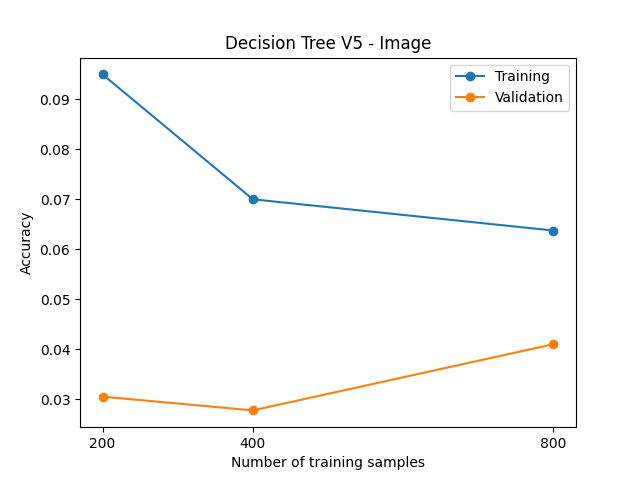

In [4]:
plt.figure()
plt.plot(training_sizes, image_summary["training_accuracy"], marker="o", label="Training")
plt.plot(training_sizes, image_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Number of training samples")
plt.ylabel("Accuracy")
plt.title("Decision Tree V5 - Image")
plt.xticks(training_sizes)
plt.legend()
plt.savefig(result_dir / "decision_tree_v5_image_training_size.png")
plt.show()


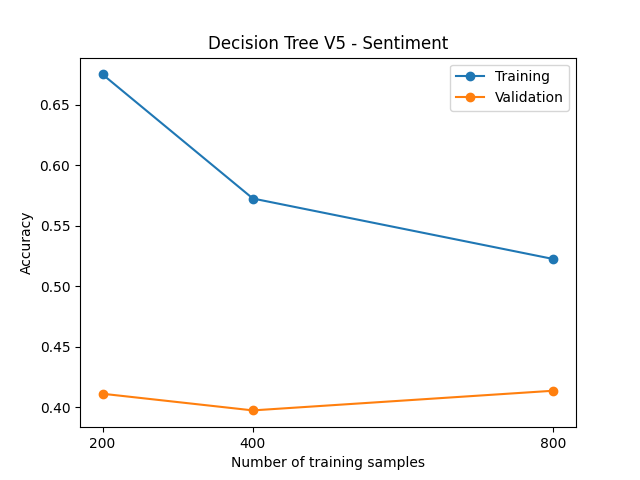

In [5]:
plt.figure()
plt.plot(training_sizes, sentiment_summary["training_accuracy"], marker="o", label="Training")
plt.plot(training_sizes, sentiment_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Number of training samples")
plt.ylabel("Accuracy")
plt.title("Decision Tree V5 - Sentiment")
plt.xticks(training_sizes)
plt.legend()
plt.savefig(result_dir / "decision_tree_v5_sentiment_training_size.png")
plt.show()


Finally, I compared the validation results to choose the best training size for each dataset.

In [6]:
image_best_accuracy = -1
for row in image_rows:
    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if row["validation_accuracy"] > image_best_accuracy:
        image_best_training_size = row["training_samples"]
        image_best_accuracy = row["validation_accuracy"]
print(f"Image: selected training size={image_best_training_size}, validation accuracy={image_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_training_size],
}).to_csv(result_dir / "decision_tree_v5_image_validation.csv", index=False)

sentiment_best_accuracy = -1
for row in sentiment_rows:
    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if row["validation_accuracy"] > sentiment_best_accuracy:
        sentiment_best_training_size = row["training_samples"]
        sentiment_best_accuracy = row["validation_accuracy"]
print(f"Sentiment: selected training size={sentiment_best_training_size}, validation accuracy={sentiment_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_training_size],
}).to_csv(result_dir / "decision_tree_v5_sentiment_validation.csv", index=False)

summary = pd.DataFrame(image_rows + sentiment_rows)
assert len(summary) == 6
summary.to_csv(result_dir / "decision_tree_v5_summary.csv", index=False)
print(summary.to_string(index=False))


Image: selected training size=800, validation accuracy=4.10%
Sentiment: selected training size=800, validation accuracy=41.38%
  dataset version criterion  max_depth  min_samples  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  fit_time_seconds  prediction_time_seconds
    image      V5   entropy          2            1       False               200                4000            0.09500              0.03050          2.160207                 0.008878
    image      V5   entropy          2            1       False               400                4000            0.07000              0.02775          8.224791                 0.008632
    image      V5   entropy          2            1       False               800                4000            0.06375              0.04100         35.514277                 0.028165
sentiment      V5   entropy          3            1       False               200                2400            0.67500             

In [7]:
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v5_row = {
    "version": "V5",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": "",
    "notes": f"Tested training sizes 200, 400, 800 with full validation sets (image 4000, sentiment 2400); selected image training size={image_best_training_size}, sentiment training size={sentiment_best_training_size}; image max_depth=2, sentiment max_depth=3, min_samples=1, entropy.",
}
matching = tracker["version"] == "V5"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, column] = v5_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v5_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle submission_filename                                                                                                                                                                                                                        notes
     V1                     0.045                          0.45                                   False                                                                                                                                                         max_depth=3, min_samples=1; 200 training examples per dataset; entropy/information gain.
     V2                     0.045                          0.45                                   False                                                                                                                Tested max_depth=2, 3, 5, 8; selected image depth=2, sentiment depth=3; min_samples=1, 200 trai

I kept 800 training samples for both datasets because it gave the highest full-validation accuracy, although sentiment improved only slightly over 200 samples. Training accuracy fell as I used more samples, and fitting took much longer, especially for sentiment.